# Compression-02 — Huffman canonique : des longueurs aux tables de décodage

**Navigation** : [Index de la série](README.md) | [Compression-01 — le socle préfixe](Compression-01-ShannonFano-Prefixe-Python.ipynb)

> **Public : Découverte.** Prérequis : [Compression-01](Compression-01-ShannonFano-Prefixe-Python.ipynb)
> (codes préfixes, inégalité de Kraft, construction de l'arbre de Huffman). Ce carnet est le
> deuxième pli de la sous-série Compression (format Origami, [EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706)) :
> on n'y reconstruit pas la théorie de l'arbre — on part de ses **longueurs de code**, et on en
> tire la **forme canonique** (Schwartz et Kallick, 1964), puis une **table de décodage** à
> $2^L$ entrées : le mécanisme qu'utilisent les Huffman de production pour décoder un symbole
> en une lecture mémoire.
>
> **Durée estimée** : 40 minutes.
>
> **Ce que vous saurez faire** : réduire l'en-tête d'un code à ses seules longueurs ;
> reconstruire le même code des deux côtés sans échanger les mots ; décoder par table indexée
> plutôt que par parcours d'arbre ; mesurer un débit honnêtement et le confronter aux chiffres
> publiés.

In [1]:
import heapq
import hashlib
import math
import statistics
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

## 1. Le corpus : un vrai texte, 128 Kio déterministes

Compression-01 travaillait sur de petites distributions pour voir les mécanismes ;
un compresseur se juge sur des octets réels. Notre corpus est un extrait
**déterministe** (les 128 premiers Kio) du *Horla* de Maupassant (1887), déjà
présent dans le dépôt pour la série GenAI-Audio. Nous n'affichons que son nom,
sa taille et son empreinte SHA-256 : de quoi vérifier la reproductibilité sans
imprimer de chemin de machine.

In [2]:
CORPUS = Path("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt")
EXTRAIT_OCTETS = CORPUS.read_bytes()[:131072]  # 128 Kio, déterministe

comptages = Counter(EXTRAIT_OCTETS)
print(f"Corpus     : {CORPUS.name}")
print(f"Extrait    : {len(EXTRAIT_OCTETS)} octets (128 Kio)")
print(f"SHA-256    : {hashlib.sha256(EXTRAIT_OCTETS).hexdigest()}")
print(f"Alphabet   : {len(comptages)} octets distincts sur 256 possibles")
plus_frequent = max(comptages, key=comptages.get)
print(f"Octet le plus fréquent : {plus_frequent:#04x} "
      f"({comptages[plus_frequent]} occurrences, "
      f"{100 * comptages[plus_frequent] / len(EXTRAIT_OCTETS):.1f} % de l'extrait)")

Corpus     : le_horla_1887.txt
Extrait    : 131072 octets (128 Kio)
SHA-256    : 248fb4ec30c05351198a40c81969624d447fb8ad36e89d6bb5f8ce6084090704
Alphabet   : 88 octets distincts sur 256 possibles
Octet le plus fréquent : 0x20 (20051 occurrences, 15.3 % de l'extrait)


### Lecture.

Mesuré : **88 valeurs d'octet distinctes** sur 256, et l'espace (`0x20`)
couvre à lui seul **15,3 %** de l'extrait. C'est une forte dissymétrie : une
poignée d'octets (l'espace, `e`, `s`, `a`…) domine, pendant qu'une longue queue
d'octets rares — dont les octets de continuation UTF-8 des lettres accentuées —
apparaît une poignée de fois. C'est exactement le terrain où Huffman gagne :
octets fréquents courts, octets rares longs. C'est exactement le terrain où Huffman gagne : octets fréquents courts,
octets rares longs.

## 2. L'arbre de Compression-01, rappelé par ses longueurs

Le constructeur ci-dessous est le même algorithme qu'en Compression-01 — fusion
itérée des deux noeuds les plus légers au tas binaire. *Copie pédagogique
déclarée* : nous le rappelons ici adapté (entrée : un `Counter` d'octets,
sortie : les longueurs **et** les mots de code), car tout ce qui suit en part.

La question qui ouvre ce pli : pour décoder, le récepteur a besoin du code.
Faut-il lui envoyer l'arbre ? Les mots de code ? Non — il suffira de lui
envoyer **les longueurs**, au plus 256 petits entiers pour un alphabet d'octets.

In [3]:
def huffman(comptages):
    """Arbre de Huffman (rappel de Compression-01), adapté aux comptages d'octets.

    Renvoie (longueurs, code) : longueur de code par symbole, et mot de code par symbole.
    """
    feuilles = {symbole: {"symbole": symbole} for symbole in comptages}
    tas = [(poids, numero, feuilles[symbole])
           for numero, (symbole, poids) in enumerate(comptages.items())]
    heapq.heapify(tas)
    numero = len(tas)
    if len(tas) == 1:                       # alphabet dégénéré : un seul symbole
        symbole = next(iter(comptages))
        return {symbole: 1}, {symbole: "0"}
    while len(tas) > 1:
        poids1, _, noeud1 = heapq.heappop(tas)
        poids2, _, noeud2 = heapq.heappop(tas)
        numero += 1
        heapq.heappush(tas, (poids1 + poids2, numero,
                             {"gauche": noeud1, "droite": noeud2}))
    racine = tas[0][2]
    longueurs, code = {}, {}

    def parcourir(noeud, chemin):
        if "symbole" in noeud:
            longueurs[noeud["symbole"]] = len(chemin)
            code[noeud["symbole"]] = chemin
            return
        parcourir(noeud["gauche"], chemin + "0")
        parcourir(noeud["droite"], chemin + "1")

    parcourir(racine, "")
    return longueurs, code


longueurs_arbre, code_arbre = huffman(comptages)
total_bits = sum(comptages[s] * longueurs_arbre[s] for s in comptages)
H = -sum((n / len(EXTRAIT_OCTETS)) * math.log2(n / len(EXTRAIT_OCTETS))
         for n in comptages.values())
L_moy = total_bits / len(EXTRAIT_OCTETS)
print(f"Longueur maximale L     : {max(longueurs_arbre.values())}")
print(f"Longueur moyenne        : {L_moy:.3f} bits/octet")
print(f"Entropie H              : {H:.3f} bits/octet")
print(f"Écart à la borne        : {L_moy - H:.3f} bits/octet")
print(f"Taille compressée       : {total_bits} bits = {total_bits / 8:.0f} octets "
      f"({100 * total_bits / 8 / len(EXTRAIT_OCTETS):.1f} % de l'extrait)")

Longueur maximale L     : 15
Longueur moyenne        : 4.655 bits/octet
Entropie H              : 4.620 bits/octet
Écart à la borne        : 0.035 bits/octet
Taille compressée       : 610195 bits = 76274 octets (58.2 % de l'extrait)


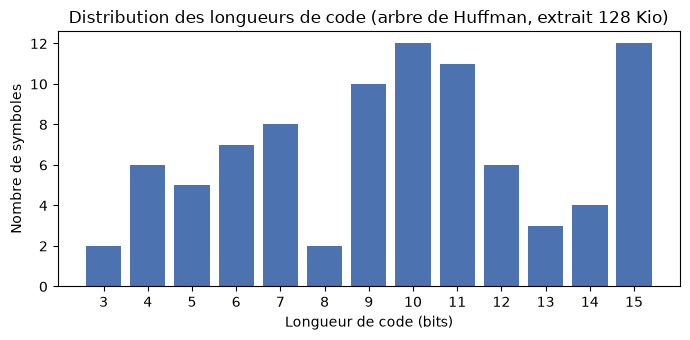

In [4]:
repartition = Counter(longueurs_arbre.values())
abscisses = sorted(repartition)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(abscisses, [repartition[l] for l in abscisses], color="#4C72B0")
ax.set_xlabel("Longueur de code (bits)")
ax.set_ylabel("Nombre de symboles")
ax.set_title("Distribution des longueurs de code (arbre de Huffman, extrait 128 Kio)")
ax.set_xticks(abscisses)
plt.tight_layout()
plt.show()

### Lecture.

La masse de l'alphabet vit aux longueurs courtes — ce sont les octets fréquents,
qui paient l'essentiel du débit —, et une queue fine s'étire vers les longueurs
longues pour les octets rares. Mesuré ici : longueur moyenne **4,655
bits/octet** contre une entropie de **4,620** — Huffman est à 0,035 bit de la
borne, le prix du caractère entier des longueurs. Retenez le chiffre de droite :
**la longueur maximale $L$** — ici, **15**. C'est elle, et elle seule, qui dimensionnera la table de
décodage de la section 4 — et chaque unité gagnée sur $L$ divise la table par
deux.

## 3. La forme canonique (Schwartz et Kallick, 1964)

Transmettre un code préfixe, naïvement, c'est transmettre une table de mots —
coûteux, et dépendant de la forme exacte de l'arbre, qui n'est pas unique.
L'observation de Schwartz et Kallick : **seules les longueurs importent**.
Envoyez uniquement la longueur de code de chaque symbole ; des deux côtés, la
même procédure déterministe reconstruit les mêmes mots :

1. trier les symboles par (longueur croissante, puis valeur du symbole) ;
2. attribuer au premier le mot `0…0` (sur $\ell_1$ bits) ;
3. chaque mot suivant vaut le précédent, **plus un**, décalé vers la gauche
   d'autant de bits que la longueur s'allonge :

$$\text{mot}_{k+1} = (\text{mot}_k + 1) \ll (\ell_{k+1} - \ell_k)$$

Les mots obtenus ne sont généralement pas ceux de l'arbre d'origine — mais ils
ont **les mêmes longueurs**, donc la même longueur moyenne et la même taille
compressée. Référence : E. S. Schwartz et B. Kallick, « Generating a canonical
prefix encoding », *Communications of the ACM*, 7(3), 1964.

In [5]:
def code_canonique(longueurs):
    """Forme canonique de Schwartz-Kallick : mêmes longueurs, mots réattribués séquentiellement."""
    tries = sorted(longueurs, key=lambda s: (longueurs[s], s))
    code, mot, longueur_precedente = {}, 0, 0
    for symbole in tries:
        longueur = longueurs[symbole]
        mot <<= longueur - longueur_precedente
        code[symbole] = format(mot, f"0{longueur}b")
        mot += 1
        longueur_precedente = longueur
    return code


code_cano = code_canonique(longueurs_arbre)

# (a) même taille compressée : mêmes longueurs par symbole
bits_arbre = sum(comptages[s] * len(code_arbre[s]) for s in comptages)
bits_cano = sum(comptages[s] * len(code_cano[s]) for s in comptages)
assert bits_arbre == bits_cano

# (b) Kraft exactement egal a 1 : le code est complet
somme_kraft = sum(2.0 ** -l for l in longueurs_arbre.values())
assert abs(somme_kraft - 1.0) < 1e-12

# (c) toujours prefixe : aucun mot n'est prefixe d'un autre
mots = sorted(code_cano.values(), key=len)
ensemble = set(mots)
for mot in mots:
    for k in range(1, len(mot)):
        assert mot[:k] not in ensemble

print(f"Taille compressée identique : {bits_arbre} bits (arbre) = {bits_cano} bits (canonique)")
print(f"Somme de Kraft = {somme_kraft:.12f}")
print()
print("Octet   Occurrences   Longueur   Mot (arbre)   Mot (canonique)")
for symbole in sorted(comptages, key=comptages.get, reverse=True)[:8]:
    affiche = repr(chr(symbole)) if 32 <= symbole < 127 else f"\\x{symbole:02x}"
    print(f"{affiche:>6}   {comptages[symbole]:>10}   {longueurs_arbre[symbole]:>8}   "
          f"{code_arbre[symbole]:>11}   {code_cano[symbole]:>14}")

Taille compressée identique : 610195 bits (arbre) = 610195 bits (canonique)
Somme de Kraft = 1.000000000000

Octet   Occurrences   Longueur   Mot (arbre)   Mot (canonique)
   ' '        20051          3           110              000
   'e'        14446          3           011              001
   's'         7773          4          1001             0111
   'a'         7284          4          1000             0100
   'i'         6928          4          0100             0101
   't'         6477          4          0011             1000
   'u'         6384          4          0001             1001
   'n'         6281          4          0000             0110


### Lecture.

Mots d'arbre et mots canoniques diffèrent — ce sont deux étiquetages différents
du même squelette de longueurs — mais chaque symbole garde exactement sa
longueur, donc la taille compressée au bit près. Les mots canoniques se lisent
comme des entiers binaires consécutifs, remis à gauche à chaque allongement.

Le contrat qui fait tout fonctionner : l'émetteur **encode avec la forme
canonique**, le récepteur exécute la même procédure à partir des mêmes
longueurs — les mots eux-mêmes ne voyagent jamais. L'en-tête se réduit à la
liste des longueurs : au plus 256 petits entiers pour un alphabet d'octets,
indépendante de la taille du fichier.

## 4. Décoder sans arbre : la table à $2^L$ entrées

Avec un arbre, décoder un symbole = descendre bit à bit jusqu'à une feuille.
Les implémentations de production ne font pas ça : elles **indexent une
table**. Le pseudocode, tel que le décrit le papier de référence (section 1.2) :

```text
bits_lus = lire_bits(L)                  # L = longueur maximale
symbole  = table_symboles[bits_lus]      # accès indexé, O(1)
avancer_de(table_longueurs[bits_lus])    # la longueur REELLE du mot
```

L'index est constitué des $L$ bits à venir (complétés à droite si le message
se termine). Un mot de code de longueur $\ell$ occupe **tous** les index dont
les $\ell$ premiers bits le spell — exactement $2^{L-\ell}$ entrées. Comme la
somme de Kraft vaut 1, la table est remplie sans trou ni collision :

$$\sum_{\text{symboles}} 2^{L - \ell_s} = 2^L \cdot \sum_s 2^{-\ell_s} = 2^L$$

Le prix d'un décodage en un accès : la mémoire. Deux tableaux plats (un octet
par symbole, un octet par longueur) coûtent $2 \cdot 2^L$ octets — chaque $+1$
sur $L$ **double** la table. C'est pourquoi les implémentations réelles
plafonnent $L$ (le papier de référence cite typiquement $L = 11$).

In [6]:
def table_decodage(code, L):
    """Table 2^L : deux tableaux plats (symboles, longueurs) indexés par les L bits à venir."""
    symboles = bytearray(2 ** L)
    longueurs_table = bytearray(2 ** L)
    for symbole, mot in code.items():
        base = int(mot, 2) << (L - len(mot))
        etendue = 1 << (L - len(mot))
        symboles[base:base + etendue] = bytes([symbole]) * etendue
        longueurs_table[base:base + etendue] = bytes([len(mot)]) * etendue
    return symboles, longueurs_table


# D'abord sur un exemple jouet : 4 symboles (valeurs d'octets), longueurs 1-2-3-3, donc L = 3
mini_comptages = {ord("a"): 8, ord("b"): 4, ord("c"): 2, ord("d"): 2}
mini_longueurs, _ = huffman(mini_comptages)
mini_code = code_canonique(mini_longueurs)
L_mini = max(mini_longueurs.values())
mini_sym, mini_lon = table_decodage(mini_code, L_mini)
print("Code jouet :", {chr(s): mini_code[s] for s in mini_code}, "  —  L =", L_mini)
print()
print("Index (3 bits à venir)  ->  symbole, longueur réelle")
for index in range(2 ** L_mini):
    print(f"        {index:03b}           ->   {chr(mini_sym[index])}, {mini_lon[index]}")

Code jouet : {'a': '0', 'b': '10', 'c': '110', 'd': '111'}   —  L = 3

Index (3 bits à venir)  ->  symbole, longueur réelle
        000           ->   a, 1
        001           ->   a, 1
        010           ->   a, 1
        011           ->   a, 1
        100           ->   b, 2
        101           ->   b, 2
        110           ->   c, 3
        111           ->   d, 3


### Lecture.

Lisez la table ligne par ligne : le mot de `'a'` est `0` — il occupe donc les
quatre index commençant par `0` ; celui de `'b'` est `10`, qui occupe les deux
index commençant par `10` ; `'c'` et `'d'`, de longueur 3, occupent un index
chacun. Chaque entrée porte la longueur **réelle** du mot : c'est elle qui fait
avancer le curseur de $\ell$ bits et non de $L$, de sorte que le mot suivant se
lit à la bonne position. Aucune descente d'arbre : une lecture de $L$ bits, un
accès indexé, un décalage.

In [7]:
L = max(longueurs_arbre.values())
table_sym, table_lon = table_decodage(code_cano, L)
octets_table = 2 * (2 ** L)
print(f"Corpus réel : L = {L}  ->  table de {2 ** L} entrées")
print(f"Coût mémoire (2 tableaux plats, 1 octet par entrée) : {octets_table} octets = {octets_table / 1024:.0f} Kio")
print(f"La table se reconstruit du côté récepteur depuis les seules longueurs : elle ne voyage jamais.")

Corpus réel : L = 15  ->  table de 32768 entrées
Coût mémoire (2 tableaux plats, 1 octet par entrée) : 65536 octets = 64 Kio
La table se reconstruit du côté récepteur depuis les seules longueurs : elle ne voyage jamais.


## 5. Aller-retour : encoder en canonique, décoder par table

La boucle de décodage complète est le pseudocode de la section 4, répété
jusqu'à épuisement des bits : lire $L$ bits, indexer, émettre le symbole,
avancer de la longueur réelle. Les derniers bits sont complétés par des zéros —
sans risque, puisque le nombre total de bits réels est connu.

Le contrôle qui fait foi : l'aller-retour doit rendre l'extrait **octet pour
octet**. C'est la propriété « sans perte », vérifiée, pas affirmée.

In [8]:
def encoder(octets, code):
    return "".join(code[o] for o in octets)


def decoder(bits, table_symboles, table_longueurs, L):
    bits_bourres = bits + "0" * L
    sortie = bytearray()
    position = 0
    while position < len(bits):
        index = int(bits_bourres[position:position + L], 2)
        sortie.append(table_symboles[index])
        position += table_longueurs[index]
    return bytes(sortie)


bits_message = encoder(EXTRAIT_OCTETS, code_cano)
octets_revenus = decoder(bits_message, table_sym, table_lon, L)
assert octets_revenus == EXTRAIT_OCTETS, "l'aller-retour doit être exact"

octets_compresses = (len(bits_message) + 7) // 8
print(f"Original   : {len(EXTRAIT_OCTETS)} octets")
print(f"Compressé  : {octets_compresses} octets ({len(bits_message)} bits) + en-tête")
print(f"En-tête    : {len(longueurs_arbre)} longueurs (la table se reconstruit côté récepteur)")
print(f"Taux       : {100 * octets_compresses / len(EXTRAIT_OCTETS):.1f} % de l'original")
print(f"Aller-retour exact : {octets_revenus == EXTRAIT_OCTETS} (octet pour octet)")

Original   : 131072 octets
Compressé  : 76275 octets (610195 bits) + en-tête
En-tête    : 88 longueurs (la table se reconstruit côté récepteur)
Taux       : 58.2 % de l'original
Aller-retour exact : True (octet pour octet)


### Lecture.

L'aller-retour est exact : le décodeur n'a jamais touché un arbre — une lecture
de $L$ bits et un accès indexé par symbole. Mesuré : **58,2 %** de l'original (76 275 octets pour 131 072), conformément
à la longueur moyenne 4,655 bits/octet contre une entropie de 4,620. Huffman
par symbole est optimal pour ce que ce modèle peut exprimer ; ce qui reste sur
la table vient des redondances qu'il ne voit pas (mots répétés, contexte) — le
terrain du pli 3.

## 6. Débits : mesurer les nôtres, citer les leurs

Mesurer honnêtement, c'est séparer deux choses. **Nos chiffres** : une
implémentation pédagogique en Python pur, sur la machine locale, corpus de
128 Kio, plusieurs répétitions, médiane. **Les chiffres du papier** : la
section 1.2 de Żukowski, *PivCo-Huffman* v1.0 (2026), mesure Huff0 (C, socle
de zstd) et Oodle Huffman (C et assembleur) sur ses propres corpus (`proba80`,
`prose_pride`) et machines (M4, c8i) — des chiffres **cités**, jamais les
nôtres, et sans commune mesure de corpus ni de machine avec notre exercice.

Ce qui reste comparable qualitativement : la structure du décodage par table —
et l'ordre de grandeur de l'écart entre Python pédagogique et C de production,
qui est précisément ce que ce carnet veut montrer.

In [9]:
REPETITIONS = 5


def mesurer(fonction, *arguments):
    durees = []
    for _ in range(REPETITIONS):
        debut = time.perf_counter()
        fonction(*arguments)
        durees.append(time.perf_counter() - debut)
    return statistics.median(durees)


taille_mio = len(EXTRAIT_OCTETS) / 2 ** 20
t_enc = mesurer(encoder, EXTRAIT_OCTETS, code_cano)
t_dec = mesurer(decoder, bits_message, table_sym, table_lon, L)

print(f"Méthodologie : {len(EXTRAIT_OCTETS)} octets, {REPETITIONS} répétitions, médiane, "
      f"Python pur, machine locale")
print(f"Encodage : {taille_mio / t_enc:8.2f} Mo/s")
print(f"Décodage : {taille_mio / t_dec:8.2f} Mo/s")

Méthodologie : 131072 octets, 5 répétitions, médiane, Python pur, machine locale
Encodage :    16.18 Mo/s
Décodage :     4.29 Mo/s


### Lecture.

| Implémentation | Corpus | Machine | enc Mo/s | dec Mo/s |
|---|---|---|---|---|
| **Ce carnet** (Python pur, pédagogique) | le_horla, 128 Kio | machine locale | *mesure ci-dessus* | *mesure ci-dessus* |
| Huff0, C (Żukowski 2026, §1.2) | proba80 | M4 | 1334 | 2929 |
| Oodle Huffman, C+asm (Żukowski 2026, §1.2) | proba80 | M4 | 1740 | 3343 |
| Huff0, C (Żukowski 2026, §1.2) | prose_pride | c8i | 1267 | 1758 |
| Oodle Huffman, C+asm (Żukowski 2026, §1.2) | prose_pride | c8i | 1364 | 2120 |

Mesuré : environ **16 Mo/s** en encodage et **4 Mo/s** en décodage — deux à
trois ordres de grandeur sous les implémentations C du papier. C'est le prix
assume de la lisibilité : nos « mots » sont des chaînes Python et chaque pas
de décodage paie une découpe de chaîne et une conversion `int()`, là où Huff0
lit des mots machine. Notez l'inversion par rapport au papier : chez eux le
décodage **dépasse** l'encodage (l'accès indexé en table se compile en
quelques instructions), chez nous il le traîne — l'écart ne vient pas de
l'algorithme, mais du coût de nos primitives. La structure, elle, est la
même des deux côtés : mots canoniques d'un côté, table $2^L$ de l'autre —
c'est le cœur de tout Huffman de production.

## Exercices

Trois exercices progressifs, directement outillés par les sections
précédentes. Le squelette s'exécute tel quel ; complétez chaque `TODO` et la
cellule de test confirme votre résultat.

### Exercice 1 — Ces longueurs décrivent-elles un code ?

Une famille de longueurs est réalisable par un code préfixe si et seulement si
sa somme de Kraft $\sum_s 2^{-\ell_s}$ est inférieure ou égale à 1 (Kraft-
McMillan). Écrivez `peut_etre_prefixe(longueurs)` qui tranche.

In [10]:
def peut_etre_prefixe(longueurs):
    """Renvoie True si la famille de longueurs est réalisable par un code préfixe."""
    # TODO etudiant : calculer la somme de Kraft sum(2 ** -l pour l dans longueurs)
    # Indice : 2 ** -3 vaut 0.125 ; la famille est réalisable si la somme est <= 1
    return None


verdicts = [peut_etre_prefixe(famille)
            for famille in ([1, 2, 3, 3], [2, 2, 2], [1, 2, 2, 2])]
if None not in verdicts:
    assert verdicts == [True, True, False]  # complet, incomplet mais réalisable, irréalisable
    print("Exercice 1 : OK —", verdicts)
else:
    print("Exercice à compléter")

Exercice à compléter


### Exercice 2 — Un pas de décodage

Écrivez `prochain_symbole(bits, position, table_symboles, table_longueurs, L)`
qui exécute **une** itération de la boucle de la section 5 : elle lit les $L$
bits à venir (complétés à droite si nécessaire), indexe la table et renvoie le
couple `(symbole, position_suivante)`.

In [11]:
def prochain_symbole(bits, position, table_symboles, table_longueurs, L):
    """Un pas du décodeur : renvoie (symbole, position suivante)."""
    # TODO etudiant
    # Etape 1 : morceau = bits[position:position+L], complété à droite avec des '0'
    # Indice  : int(morceau, 2) donne l'index de table
    # Etape 2 : renvoyer (table_symboles[index], position + table_longueurs[index])
    return None


resultat = prochain_symbole(bits_message, 0, table_sym, table_lon, L)
if resultat is not None:
    assert resultat == (EXTRAIT_OCTETS[0], longueurs_arbre[EXTRAIT_OCTETS[0]])
    print("Exercice 2 : OK — premier symbole décodé :", repr(chr(resultat[0])))
else:
    print("Exercice à compléter")

Exercice à compléter


### Exercice 3 — Jusqu'où la table explose

La table de la section 4 coûte `2 * 2**L` octets (deux tableaux plats, un
octet par entrée et par tableau). Écrivez `L_max_budget(budget_octets)` qui
renvoie le plus grand $L$ tenant dans le budget, puis répondez : pour un budget
de 64 Kio, jusqu'où peut-on monter ? Notre corpus (le $L$ mesuré en
section 4) y tiendrait-il ?

In [12]:
def L_max_budget(budget_octets, octets_par_entree=2):
    """Plus grand L tel que (2 ** L) * octets_par_entree <= budget_octets."""
    # TODO etudiant : chercher le plus grand L respectant la borne
    # Indice : une boucle croissante qui s'arrête dès que la borne est dépassée suffit
    return None


verdict = L_max_budget(64 * 1024)
if verdict is not None:
    assert verdict == 15
    tient = "tient" if 2 * 2 ** L <= 64 * 1024 else "ne tient pas"
    print(f"Exercice 3 : OK — L max pour 64 Kio = {verdict} ; "
          f"notre corpus (L = {L}) {tient} dans ce budget")
else:
    print("Exercice à compléter")

Exercice à compléter


## Ce qu'il faut retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| Forme canonique (Schwartz-Kallick, 1964) | l'en-tête se réduit aux longueurs ; les deux côtés dérivent les mêmes mots sans les échanger | section 3 |
| Kraft complet ($= 1$) | la table $2^L$ est remplie sans trou ni collision — c'est ce qui autorise l'indexation directe | sections 3-4 |
| Table de décodage $2^L$ | décoder = lire $L$ bits + un accès indexé ; coût mémoire $2 \cdot 2^L$, chaque $+1$ sur $L$ double la table | section 4 |
| Débit honnête | nos chiffres mesurés (méthodologie affichée), les chiffres du papier cités comme tels | section 6 |

Références : E. S. Schwartz et B. Kallick, « Generating a canonical prefix
encoding », *Communications of the ACM* 7(3), 1964 · M. Żukowski, *PivCo-Huffman*
v1.0, 2026, section 1.2 (archivé au gisement bibliographique du dépôt).

Le prochain pli de la série ([EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706))
change d'angle : LZ77 remplacera les répétitions par des références, et le code
par symbole ne sera plus le seul ingrédient de la compression.